In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
# Đọc dữ liệu
# Bước này dùng để nạp dữ liệu đã được nhóm em tiền xử lý trước
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Đọc file dữ liệu từ thư mục input của Kaggle
df = pd.read_csv('/kaggle/input/datasets/darkin745/depression-processed-data/train_preprocessed.csv')

# Chia dữ liệu thành các biến đặc trưng (X) và nhãn mục tiêu (y)
X = df.drop('Depression', axis=1)
y = df['Depression']

# Chia tập dữ liệu thành 80% để học (train) và 20% để kiểm tra lại (validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print("Đã tải dữ liệu thành công. Kích thước tập train:", X_train.shape)

Đã tải dữ liệu thành công. Kích thước tập train: (112560, 28)


In [2]:
#  XÂY DỰNG MÔ HÌNH RANDOM FOREST
# Em sử dụng thuật toán Random Forest 
# Ở đây em thiết lập 200 cây quyết định và độ sâu tối đa là 10 
model_rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)

# Bắt đầu quá trình huấn luyện mô hình trên dữ liệu tập train
model_rf.fit(X_train, y_train)

# Dự đoán thử trên tập validation để đánh giá độ chính xác
y_pred = model_rf.predict(X_val)

# In ra các chỉ số đánh giá để xem model hiệu quả không
print("Độ chính xác tổng thể (Accuracy):", accuracy_score(y_val, y_pred))
print("\nBáo cáo chi tiết các chỉ số:")
print(classification_report(y_val, y_pred))

Độ chính xác tổng thể (Accuracy): 0.9205401563610519

Báo cáo chi tiết các chỉ số:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95     22986
           1       0.80      0.75      0.78      5154

    accuracy                           0.92     28140
   macro avg       0.87      0.85      0.86     28140
weighted avg       0.92      0.92      0.92     28140



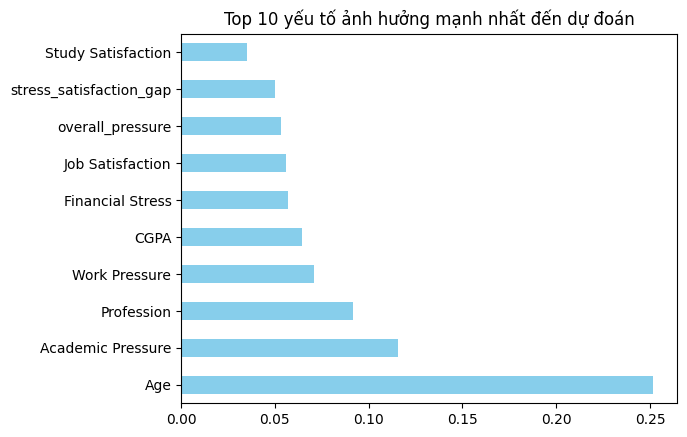

In [3]:
#  PHÂN TÍCH CÁC FEARTURES
# Em vẽ biểu đồ này để tìm ra những yếu tố nào ảnh hưởng nhiều nhất đến việc dự đoán trầm cảm
importances = pd.Series(model_rf.feature_importances_, index=X.columns)
importances.nlargest(10).plot(kind='barh', color='skyblue')
plt.title('Top 10 yếu tố ảnh hưởng mạnh nhất đến dự đoán')
plt.show()

In [5]:
#  DỰ ĐOÁN TẬP TEST 
import pandas as pd

# 1. Đọc dữ liệu test và file mẫu
df_test = pd.read_csv('/kaggle/input/datasets/darkin745/depression-processed-data/test_preprocessed.csv')
submission = pd.read_csv('/kaggle/input/competitions/playground-series-s4e11/sample_submission.csv')

if 'id' in df_test.columns:
    X_test = df_test.drop('id', axis=1)
else:
    X_test = df_test

# 2. Dự đoán bằng mô hình trên tập dữ liệu 
y_test_pred = model_rf.predict(X_test)

# 3. Gắn kết quả dự đoán vào cột 'Depression' của file nộp bài
submission['Depression'] = y_test_pred

# 4. Xuất ra file CSV
submission.to_csv('submission.csv', index=False)
print(" Tạo file submission.csv thành công.")

 Tạo file submission.csv thành công.
